# Chapitre 3 - Exercices 3.1 à 3.6

Ce notebook traite les six premiers exercices du chapitre 3, centrés sur les métriques
de modélisation du langage et l'évaluation exacte :

- **3.1** : bornes de l'entropie et langue du carré non uniforme (démonstration et calcul) ;
- **3.2** : conversions entre entropie croisée, BPC, BPB et perplexité, sur le tableau 3-1
  du livre puis sur de vrais modèles ;
- **3.3** : minimiser l'entropie croisée, c'est faire du maximum de vraisemblance ; KL
  directe contre KL inverse ;
- **3.4** : contamination sous paraphrase, et test de complétion de préfixe (mini-lab) ;
- **3.5** : pass@k, calculs à la main, variance de l'estimateur et significativité ;
- **3.6** : construire un vérificateur de réponses courtes plus robuste que la
  correspondance exacte (mini-lab).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import ch03_evaluation as ev
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                          annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
rng = np.random.default_rng(0)
llm.seed_everything(0)
pd.set_option("display.precision", 4)
QWEN_BASE = "Qwen/Qwen2.5-0.5B"

## Exercice 3.1 : Bornes de l'entropie et langue du carré

**Énoncé.**

1. Montrer que pour toute loi $P$ sur un vocabulaire de $V$ symboles,
   $0 \le H(P) \le \log_2 V$, et préciser les cas d'égalité.
2. Dans la langue (b) du livre (quatre tokens *haut-gauche*, *haut-droite*, *bas-gauche*,
   *bas-droite*), on suppose que les positions du haut sont trois fois plus fréquentes que
   celles du bas, et que gauche et droite sont équiprobables. Calculer l'entropie et la
   perplexité de cette langue.
3. Montrer que si deux variables $X$ (haut/bas) et $Y$ (gauche/droite) sont
   indépendantes, $H(X, Y) = H(X) + H(Y)$, et vérifier le résultat de la question 2.

**Rappels.** Entropie $H(P) = -\sum_x P(x)\log_2 P(x)$ ; entropie croisée
$H(P, Q) = H(P) + D_{KL}(P\|Q)$ avec $D_{KL} \ge 0$ (inégalité de Gibbs) ; perplexité
$2^{H}$ (section *Entropy* et *Perplexity*, cours 1, sections 2 à 4).

**Solution.**

*1. Borne inférieure.* Chaque terme $-P(x)\log_2 P(x)$ est positif car $0 \le P(x) \le 1$.
Il est nul si et seulement si $P(x) \in \{0, 1\}$ : $H(P) = 0$ ssi $P$ est un Dirac (un
seul symbole possible, aucune surprise).

*Borne supérieure.* Prenons $U$ la loi uniforme sur les $V$ symboles. Alors
$H(P, U) = -\sum_x P(x)\log_2 \frac1V = \log_2 V$. Par la décomposition
$H(P, U) = H(P) + D_{KL}(P\|U)$ et $D_{KL} \ge 0$ :
$H(P) \le \log_2 V$, avec égalité ssi $D_{KL}(P\|U) = 0$, c'est-à-dire $P = U$.

*2.* $P(\text{haut}) = 3/4$, $P(\text{bas}) = 1/4$, et chaque moitié se partage
également entre gauche et droite : les quatre probabilités sont
$(3/8, 3/8, 1/8, 1/8)$. Donc
$$H = -2\cdot\tfrac38\log_2\tfrac38 - 2\cdot\tfrac18\log_2\tfrac18 = \tfrac34\log_2\tfrac83 + \tfrac14\cdot 3 \approx 0{,}811 + 1 = 1{,}811 \text{ bit},$$
et la perplexité vaut $2^{1{,}811} \approx 3{,}51$ : un peu moins que les 4 options de la
version uniforme.

*3.* Si $P(x, y) = P(x)P(y)$, alors
$-\log P(x,y) = -\log P(x) - \log P(y)$ ; en prenant l'espérance,
$H(X, Y) = H(X) + H(Y)$. Ici $H(X) = H(3/4, 1/4) \approx 0{,}811$ et $H(Y) = 1$ : on
retrouve $1{,}811$ bit. L'entropie (comme la log-vraisemblance) est **additive** sur des
événements indépendants, ce qui justifie de sommer les surprises des tokens. $\blacksquare$

**Vérification numérique** : les calculs, puis l'entropie de 2 000 lois aléatoires
(Dirichlet) sur $V$ symboles, toujours sous la borne $\log_2 V$.

H = 1.8113 bit ; PPL = 3.510 ; H(X) + H(Y) = 1.8113


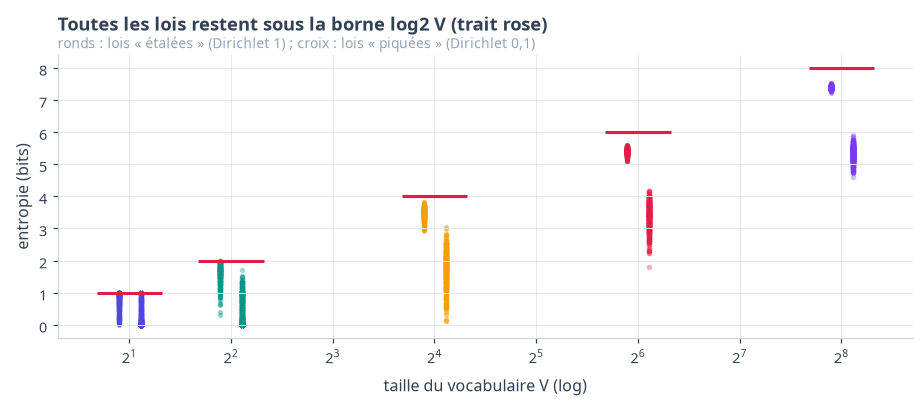

In [2]:
p4 = np.array([3, 3, 1, 1]) / 8
print(f"H = {ev.entropy(p4):.4f} bit ; PPL = {2 ** ev.entropy(p4):.3f} ; "
      f"H(X) + H(Y) = {ev.entropy([0.75, 0.25]) + ev.entropy([0.5, 0.5]):.4f}")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for V, c in zip([2, 4, 16, 64, 256], COLORS):
    for alpha, mk in [(1.0, "o"), (0.1, "x")]:
        h = [ev.entropy(rng.dirichlet(np.full(V, alpha))) for _ in range(400)]
        ax.scatter(np.full(400, V) * (1.08 if alpha == 0.1 else 0.93), h, s=6, color=c, alpha=0.35, marker=mk)
    ax.hlines(math.log2(V), V * 0.8, V * 1.25, color=ROSE, lw=2)
ax.set_xscale("log", base=2); ax.set_xlabel("taille du vocabulaire V (log)"); ax.set_ylabel("entropie (bits)")
ax.set_title("Toutes les lois restent sous la borne log2 V (trait rose)")
subtitle(ax, "ronds : lois « étalées » (Dirichlet 1) ; croix : lois « piquées » (Dirichlet 0,1)")
plt.tight_layout(); plt.show()

> **À retenir.** $0 \le H(P) \le \log_2 V$ : l'entropie est nulle pour une langue
> parfaitement prévisible, maximale pour une langue uniforme, et additive sur des
> composantes indépendantes.

## Exercice 3.2 : Conversions entre CE, BPC, BPB et perplexité

**Énoncé.**

1. Le tableau 3-1 du livre indique pour GPT-2 (1 542 M paramètres) un BPB de 0,93 sur
   enwik8 et un BPC de 0,98 sur text8. Quel taux de compression le premier chiffre
   représente-t-il ? Quelle perplexité par caractère le second ?
2. Un modèle annonce une perplexité de 12 par token sur un corpus anglais (ASCII,
   1 octet par caractère, 4,3 caractères par token), et de 20 par token sur un corpus
   français (UTF-8, 1,04 octet par caractère en moyenne, 3,4 caractères par token). Sur
   quel corpus est-il le meilleur « compresseur » ?
3. Vérifier sur GPT-2 et Qwen2.5 l'identité
   $\mathrm{BPB} = \log_2(\mathrm{PPL}) \cdot N / B$ ($N$ tokens, $B$ octets) sur un texte
   anglais et un texte français.

**Rappels.** $\mathrm{CE}_{\text{bits}} = \log_2 \mathrm{PPL}$,
$\mathrm{BPC} = \mathrm{CE}_{\text{bits}}/(\text{caractères par token})$,
$\mathrm{BPB} = \mathrm{BPC}/(\text{octets par caractère})$ (sections
*Bits-per-Character and Bits-per-Byte* et *Perplexity*, cours 1 section 4).

**Solution.**

*1.* Un BPB de 0,93 signifie 0,93 bit par octet de 8 bits : le texte compressé occupe
$0{,}93/8 \approx 11{,}6\,\%$ de sa taille, un taux de compression d'environ 8,6 (gzip
fait environ 3 sur ce type de texte). Un BPC de 0,98 donne une perplexité par caractère
$2^{0{,}98} \approx 1{,}97$ : le modèle hésite en moyenne entre deux caractères à peine.

*2.* Anglais : $\log_2 12 = 3{,}585$ bits/token, soit $3{,}585/4{,}3 = 0{,}834$ BPC et
autant de BPB. Français : $\log_2 20 = 4{,}322$ bits/token, $4{,}322/3{,}4 = 1{,}271$
BPC, $1{,}271/1{,}04 = 1{,}222$ BPB. Le modèle compresse mieux l'anglais (0,83 contre
1,22 bit par octet). Comparer « 12 » et « 20 » aurait été trompeur dans l'autre sens
aussi : les tokens n'ont pas la même longueur.

*3.* En notant $L$ la NLL totale, $\log_2 \mathrm{PPL} = L/(N\ln 2)$ et
$\mathrm{BPB} = L/(B\ln 2)$, d'où l'identité. $\blacksquare$

In [3]:
def conv(ppl, chars_per_tok, bytes_per_char):
    ce = math.log2(ppl)
    bpc = ce / chars_per_tok
    return dict(ce_bits=ce, bpc=bpc, bpb=bpc / bytes_per_char, compression=8 / (bpc / bytes_per_char))


pd.DataFrame({"anglais (PPL 12)": conv(12, 4.3, 1.0), "français (PPL 20)": conv(20, 3.4, 1.04)}).T

,ce_bits,bpc,bpb,compression
anglais (PPL 12),3.5850,0.8337,0.8337,9.5956
français (PPL 20),4.3219,1.2712,1.2223,6.5452


**Vérification** de l'identité sur de vrais modèles.

In [4]:
textes = {"anglais": ev.FRESH_TEXTS["Récit (inédit)"],
          "français": ("Chaque automne, la petite ville côtière organise une fête pour célébrer le retour des bateaux "
                       "de pêche ; les familles se retrouvent sur le port et partagent un long repas.")}
rows = []
for langue, t in textes.items():
    for mod, mid in [("GPT-2", llm.BASE), ("Qwen2.5 base", QWEN_BASE)]:
        m = ev.text_metrics(t, mid)
        rows.append(dict(texte=langue, modele=mod, N=m.n_tokens, B=m.n_bytes, ppl=m.ppl, bpb=m.bpb,
                         identite=math.log2(m.ppl) * m.n_tokens / m.n_bytes))
V32 = pd.DataFrame(rows)
V32

,texte,modele,N,B,ppl,bpb,identite
0,anglais,GPT-2,52,263,62.3482,1.1789,1.1789
1,anglais,Qwen2.5 base,53,263,47.5328,1.1226,1.1226
2,français,GPT-2,55,177,172.6218,2.3092,2.3092
3,français,Qwen2.5 base,48,177,13.8814,1.0292,1.0292


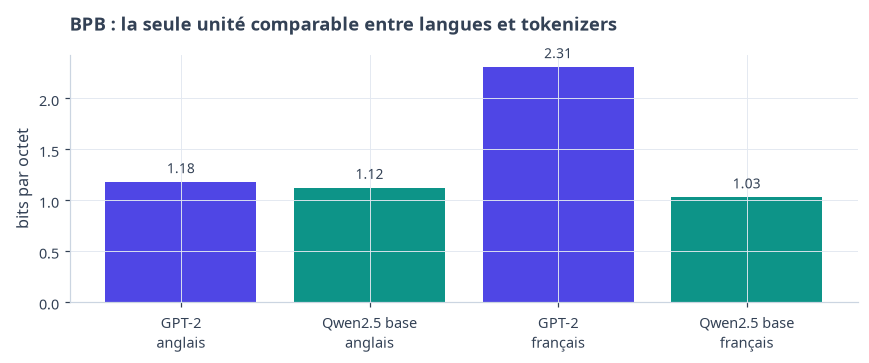

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
lab = [f"{r.modele}\n{r.texte}" for r in V32.itertuples()]
ax.bar(lab, V32.bpb, color=[INDIGO, TEAL, INDIGO, TEAL])
annotate_bars(ax, "{:.2f}")
ax.set_ylabel("bits par octet"); ax.set_title("BPB : la seule unité comparable entre langues et tokenizers")
plt.tight_layout(); plt.show()

Les colonnes `bpb` et `identite` coïncident. GPT-2 et Qwen ont des BPB voisins sur
l'anglais ; sur le français, GPT-2 (entraîné quasi uniquement en anglais) s'effondre.

> **À retenir.** Pour comparer des modèles ou des corpus, convertir en bits par octet.
> Une perplexité par token n'est qu'une étape de calcul, liée au tokenizer.

## Exercice 3.3 : Entropie croisée, maximum de vraisemblance, KL directe et inverse

**Énoncé.**

1. On observe $N$ tokens tirés d'un vocabulaire de $V$ symboles, avec $n_v$ occurrences
   du symbole $v$. Montrer que le modèle catégoriel $q$ qui minimise l'entropie croisée
   empirique $-\frac1N\sum_v n_v \log q_v$ est $q_v = n_v / N$.
2. On paramètre $q = \mathrm{softmax}(z)$. Montrer que le gradient de l'entropie croisée
   par rapport à $z$ vaut $q - \hat p$ ($\hat p$ : fréquences empiriques), et le vérifier
   par une descente de gradient.
3. On approche une loi bimodale $P$ par une loi normale $Q$. Comparer la loi obtenue en
   minimisant $D_{KL}(P\|Q)$ (ce que fait l'entraînement par entropie croisée) et en
   minimisant $D_{KL}(Q\|P)$.

**Rappels.** $H(P, Q) = H(P) + D_{KL}(P\|Q)$ : à $P$ fixée, minimiser l'entropie croisée
en $Q$ revient à minimiser $D_{KL}(P\|Q)$ (section *Cross Entropy*, cours 1 section 3).
Softmax : $q_v = e^{z_v}/\sum_u e^{z_u}$.

**Solution.**

*1.* On minimise $f(q) = -\sum_v n_v\log q_v$ sous la contrainte $\sum_v q_v = 1$.
Lagrangien : $\mathcal L = -\sum_v n_v\log q_v + \lambda(\sum_v q_v - 1)$. En annulant
$\partial\mathcal L/\partial q_v = -n_v/q_v + \lambda$, on obtient $q_v = n_v/\lambda$,
et la contrainte donne $\lambda = N$. La fonction étant convexe, c'est le minimum :
**le modèle d'entropie croisée minimale est l'estimateur du maximum de vraisemblance**
(les fréquences). Pour un réseau de neurones, le principe est le même, sous la
contrainte de la paramétrisation.

*2.* $\mathrm{CE}(z) = -\sum_v \hat p_v \log q_v = -\sum_v \hat p_v z_v + \log\sum_u e^{z_u}$.
Donc $\partial \mathrm{CE}/\partial z_v = -\hat p_v + e^{z_v}/\sum_u e^{z_u} = q_v - \hat p_v$.
C'est le célèbre gradient « prédiction moins cible » de la couche de sortie d'un modèle
de langage.

*3.* Pour une normale, minimiser $D_{KL}(P\|Q)$ revient à égaler moyenne et variance de
$P$ (« moment matching ») : $Q$ **couvre** les deux modes, quitte à mettre de la masse
entre eux. Minimiser $D_{KL}(Q\|P) = \mathbb E_Q[\log Q - \log P]$ pénalise fortement
toute masse de $Q$ là où $P$ est faible : $Q$ **choisit un mode**. $\blacksquare$

In [6]:
# Questions 1 et 2 : descente de gradient sur les logits
comptes = np.array([50, 30, 15, 4, 1])
p_hat = comptes / comptes.sum()
z = np.zeros(5)
traj = []
for t in range(300):
    q = llm.softmax(z)
    traj.append(ev.cross_entropy(p_hat, q))
    z -= 1.0 * (q - p_hat)
q_final = llm.softmax(z)
print("fréquences :", p_hat.round(4), "\nsoftmax(z) :", q_final.round(4))
eps = 1e-6
g_num = np.array([(ev.cross_entropy(p_hat, llm.softmax(z + eps * np.eye(5)[v]), base=math.e) -
                   ev.cross_entropy(p_hat, llm.softmax(z - eps * np.eye(5)[v]), base=math.e)) / (2 * eps) for v in range(5)])
print("gradient numérique :", g_num.round(6), " | q - p_hat :", (llm.softmax(z) - p_hat).round(6))

fréquences : [0.5  0.3  0.15 0.04 0.01] 
softmax(z) : [0.4999 0.2999 0.1499 0.0399 0.0102]
gradient numérique : [-5.00e-05 -5.10e-05 -5.40e-05 -7.20e-05  2.27e-04]  | q - p_hat : [-5.00e-05 -5.10e-05 -5.40e-05 -7.20e-05  2.27e-04]


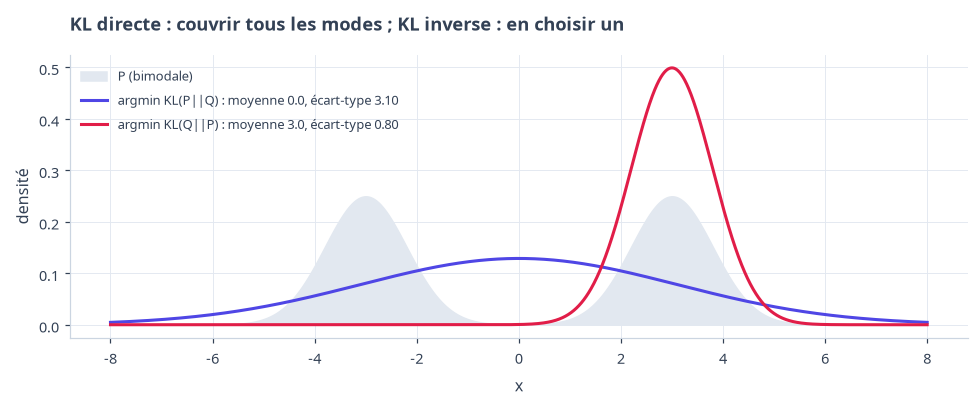

In [7]:
# Question 3 : KL directe contre KL inverse sur une grille
x = np.linspace(-8, 8, 2001)
dx = x[1] - x[0]
normal = lambda m, s: np.exp(-0.5 * ((x - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
P = 0.5 * normal(-3, 0.8) + 0.5 * normal(3, 0.8)


def kl(a, b):
    m = a > 1e-300
    return float(np.sum(a[m] * (np.log(a[m]) - np.log(np.maximum(b[m], 1e-300)))) * dx)


grille = [(m, s) for m in np.linspace(-4, 4, 81) for s in np.linspace(0.3, 4.5, 85)]
fwd = min(grille, key=lambda g: kl(P, normal(*g)))
rev = min(grille, key=lambda g: kl(normal(*g), P))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(x, P, color=LIGHT[SLATE], label="P (bimodale)")
ax.plot(x, normal(*fwd), color=INDIGO, label=f"argmin KL(P||Q) : moyenne {fwd[0]:.1f}, écart-type {fwd[1]:.2f}")
ax.plot(x, normal(*rev), color=ROSE, label=f"argmin KL(Q||P) : moyenne {rev[0]:.1f}, écart-type {rev[1]:.2f}")
ax.set_xlabel("x"); ax.set_ylabel("densité")
ax.set_title("KL directe : couvrir tous les modes ; KL inverse : en choisir un")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()

La descente de gradient retrouve les fréquences empiriques et le gradient numérique
coïncide avec $q - \hat p$. L'expérience bimodale illustre pourquoi un modèle pré-entraîné
par entropie croisée (KL directe) tend à **couvrir** toute la diversité des données,
alors que des objectifs de type KL inverse, que l'on retrouve dans certaines méthodes
d'alignement, favorisent des distributions plus **concentrées**. C'est une intuition
(pas une démonstration) de l'« effondrement de l'entropie » après post-entraînement
évoqué par le livre et mesuré au cours 1.

> **À retenir.** Minimiser l'entropie croisée = maximiser la vraisemblance = minimiser
> $D_{KL}(P\|Q)$ ; le gradient en sortie est « prédiction moins cible ». La KL directe
> couvre les modes, la KL inverse les sélectionne.

## Exercice 3.4 : Contamination sous paraphrase et test de complétion

**Énoncé.** Un auditeur soupçonne qu'un benchmark a fuité dans les données
d'entraînement de Qwen2.5-0.5B (modèle de base). On simule le benchmark par les six
textes célèbres de `ev.MEMORIZED_TEXTS`.

1. Mesurer la perplexité et le score Min-20 % quand une fraction croissante des mots
   (0 %, 10 %, 20 %, 40 %) est remplacée, puis quand l'ordre des mots est mélangé.
   Comparer aux textes inédits. À partir de quel degré de modification la détection
   échoue-t-elle ?
2. Un second test consiste à donner au modèle la **première moitié** d'un texte et à
   regarder s'il en **récite** la suite (décodage glouton). Mesurer la similarité
   d'édition entre la suite générée et la vraie suite, pour les textes célèbres et pour
   les textes inédits.

**Rappels.** Perplexité basse = texte probablement vu ; Min-K% Prob = moyenne des $k\,\%$
log-probabilités les plus basses (section *Perplexity Interpretation and Use Cases*,
cours 1 section 7). Similarité d'édition = $1 - $ distance / longueur (cours 2).

**Solution.** On mesure, puis on compare à la distribution des textes inédits (seuil :
le plus bas des scores inédits).

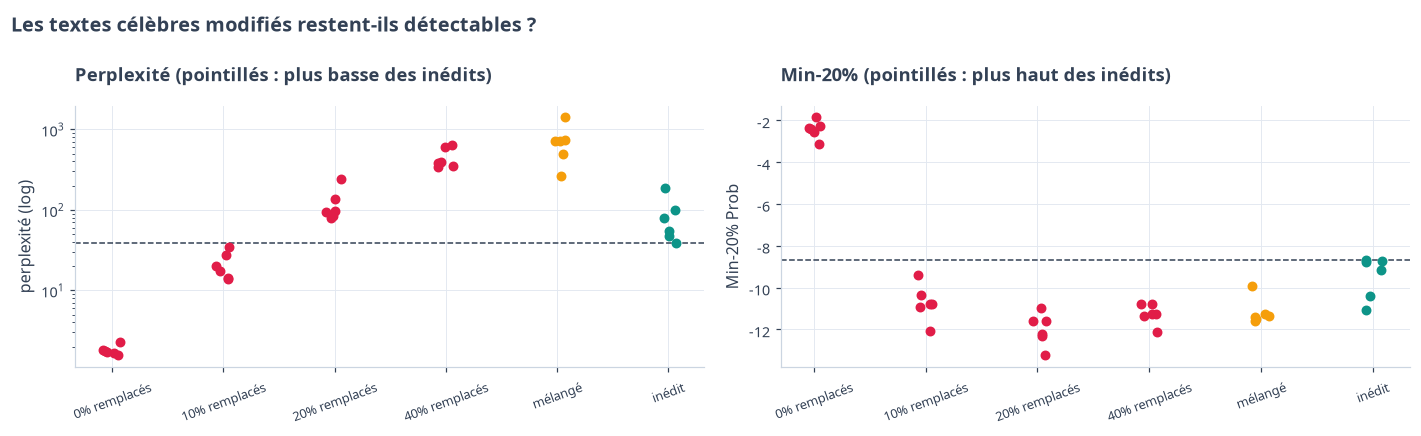

,détectés (PPL),détectés (Min-20%)
variante,,
0% remplacés,1.0,1.0
10% remplacés,1.0,0.0
20% remplacés,0.0,0.0
40% remplacés,0.0,0.0
mélangé,0.0,0.0


In [8]:
rows = []
for nom, t in ev.MEMORIZED_TEXTS.items():
    for frac in [0.0, 0.1, 0.2, 0.4]:
        tt = t if frac == 0 else ev.perturb_words(t, frac, seed=1)
        m = ev.text_metrics(tt, QWEN_BASE)
        rows.append(dict(texte=nom, variante=f"{frac:.0%} remplacés", ppl=m.ppl, mink=ev.min_k_prob(m.logprobs)))
    m = ev.text_metrics(ev.shuffle_words(t, seed=1), QWEN_BASE)
    rows.append(dict(texte=nom, variante="mélangé", ppl=m.ppl, mink=ev.min_k_prob(m.logprobs)))
for nom, t in ev.FRESH_TEXTS.items():
    m = ev.text_metrics(t, QWEN_BASE)
    rows.append(dict(texte=nom, variante="inédit", ppl=m.ppl, mink=ev.min_k_prob(m.logprobs)))
C = pd.DataFrame(rows)
ordre = ["0% remplacés", "10% remplacés", "20% remplacés", "40% remplacés", "mélangé", "inédit"]
seuil_ppl = C[C.variante == "inédit"].ppl.min()
seuil_mink = C[C.variante == "inédit"].mink.max()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, seuil, lab in [(axes[0], "ppl", seuil_ppl, "perplexité (log)"), (axes[1], "mink", seuil_mink, "Min-20% Prob")]:
    for i, v in enumerate(ordre):
        vals = C[C.variante == v][col]
        ax.scatter(np.full(len(vals), i) + rng.uniform(-0.08, 0.08, len(vals)), vals,
                   color=TEAL if v == "inédit" else (AMBER if v == "mélangé" else ROSE), s=30, zorder=3)
    ax.axhline(seuil, color=SLATE, ls="--", lw=1)
    ax.set_xticks(range(len(ordre))); ax.set_xticklabels(ordre, rotation=20, fontsize=8.5); ax.set_ylabel(lab)
axes[0].set_yscale("log"); axes[0].set_title("Perplexité (pointillés : plus basse des inédits)")
axes[1].set_title("Min-20% (pointillés : plus haut des inédits)")
finish(fig, "Les textes célèbres modifiés restent-ils détectables ?")
plt.show()
det = C[C.variante != "inédit"].groupby("variante").apply(
    lambda g: pd.Series({"détectés (PPL)": np.mean(g.ppl < seuil_ppl), "détectés (Min-20%)": np.mean(g.mink > seuil_mink)}),
    include_groups=False).loc[ordre[:-1]]
det

La détection est fragile. Avec un seuil strict (aucun faux positif sur les textes
inédits), Min-K% ne détecte plus rien dès 10 % de mots remplacés : il se concentre sur
les tokens les plus surprenants, qui sont justement les mots remplacés. La perplexité
moyenne résiste à 10 % de remplacements (le modèle « reconnaît » le texte autour des mots
changés) mais échoue à partir de 20 % environ ; le mélange des mots détruit toute trace
exploitable. Les textes modifiés restent pourtant plus prévisibles que les textes
mélangés : le signal ne disparaît pas, il passe sous le seuil des textes inédits les plus
faciles. Une contamination par **paraphrase** profonde (même contenu,
toutes les phrases réécrites) serait encore plus difficile à détecter par la perplexité :
c'est une limite connue de ces méthodes.

**Question 2 : test de complétion de préfixe.**

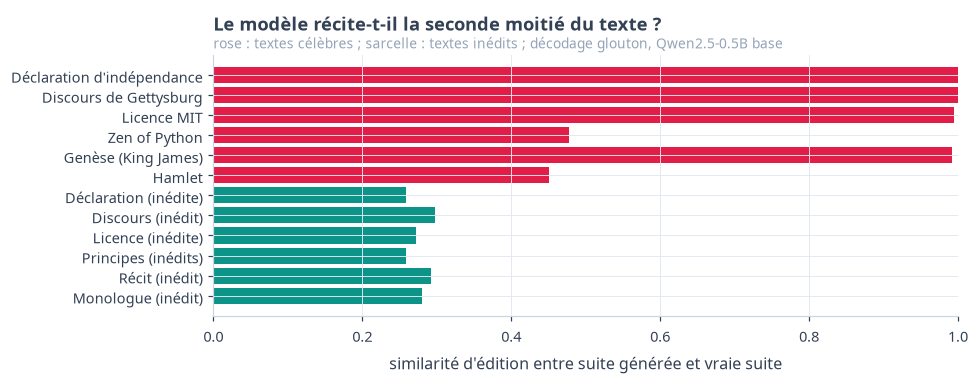

,famille,texte,similarite,debut_genere
0,célèbre,Déclaration d'indépendance,1.0000,and equal station to which the Laws of Nature ...
1,célèbre,Discours de Gettysburg,1.0000,are created equal. Now we are engaged in a gre...
2,célèbre,Licence MIT,0.9943,"in the Software without restriction, including..."
3,célèbre,Zen of Python,0.4773,Flat is better than vertical. Two is better th...
4,célèbre,Genèse (King James),0.9917,the deep. And the Spirit of God moved upon the...
5,célèbre,Hamlet,0.4503,take arms against a sea of troubles (1776) by ...
6,inédit,Déclaration (inédite),0.2585,the situation. The letter should be sent to th...
7,inédit,Discours (inédit),0.2977,wanted. The library was a place of refuge for ...
8,inédit,Licence (inédite),0.2727,the recipe is included. The recipe cards are a...
9,inédit,Principes (inédits),0.2590,beat noisy ones. A well-organized team beats a...


In [9]:
def completion(texte, model_id=QWEN_BASE):
    mots = texte.split()
    prefixe, suite = " ".join(mots[:len(mots) // 2]), " ".join(mots[len(mots) // 2:])
    gen = llm.complete(prefixe, model_id, max_new_tokens=len(llm.load(model_id)[0](suite)["input_ids"]) + 5)
    gen = " ".join(gen.split()[:len(suite.split())])
    return suite, gen, ev.edit_similarity(gen.lower(), suite.lower())


rows = []
for fam, dico in [("célèbre", ev.MEMORIZED_TEXTS), ("inédit", ev.FRESH_TEXTS)]:
    for nom, t in dico.items():
        suite, gen, simi = completion(t)
        rows.append(dict(famille=fam, texte=nom, similarite=simi, debut_genere=gen[:60]))
CP = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh([f"{r.texte}" for r in CP.itertuples()][::-1], CP.similarite[::-1],
        color=[ROSE if f == "célèbre" else TEAL for f in CP.famille][::-1])
ax.set_xlabel("similarité d'édition entre suite générée et vraie suite"); ax.set_xlim(0, 1)
ax.set_title("Le modèle récite-t-il la seconde moitié du texte ?")
subtitle(ax, "rose : textes célèbres ; sarcelle : textes inédits ; décodage glouton, Qwen2.5-0.5B base")
plt.tight_layout(); plt.show()
CP[["famille", "texte", "similarite", "debut_genere"]]

Pour plusieurs textes célèbres, le modèle récite la suite presque mot pour mot (une
similarité proche de 1 est impossible par hasard) ; pour les textes inédits, la suite
générée est plausible mais différente. Ce test est plus démonstratif que la perplexité
(une récitation mot pour mot est une preuve forte de mémorisation), mais il ne détecte
que la mémorisation **littérale** et nécessite des textes assez longs.

> **À retenir.** La perplexité et Min-K% détectent les textes vus même légèrement
> modifiés, pas les textes réécrits. Le test de complétion fournit une preuve forte, mais
> seulement de mémorisation littérale. Aucun test n'innocente un benchmark.

## Exercice 3.5 : pass@k, calculs et significativité

**Énoncé.**

1. Pour un problème, on a généré $n = 10$ programmes dont $c = 3$ corrects. Calculer à la
   main pass@1, pass@3 et pass@5 avec l'estimateur non biaisé.
2. Montrer que pour $k = 1$, l'estimateur vaut $c/n$.
3. Pour un problème de difficulté $p = 0{,}05$, tracer l'écart-type de
   $\widehat{\text{pass@}10}$ en fonction de $n$. Quel $n$ faut-il pour un écart-type
   inférieur à 0,1 ?
4. Sur un banc de 164 problèmes (la taille de HumanEval), un modèle A obtient
   pass@1 = 45 % et un modèle B 48 %. L'écart est-il significatif ?

**Rappels.** $\widehat{\text{pass@}k} = 1 - \binom{n-c}{k}/\binom nk$, sans biais pour
$1 - (1-p)^k$ (section *Functional Correctness*, cours 2 section 3).

**Solution.**

*1.* $\binom{10}{1} = 10$, $\binom 71 = 7$ : pass@1 $= 1 - 7/10 = 0{,}3$.
$\binom{10}3 = 120$, $\binom73 = 35$ : pass@3 $= 1 - 35/120 \approx 0{,}708$.
$\binom{10}5 = 252$, $\binom75 = 21$ : pass@5 $= 1 - 21/252 \approx 0{,}917$.

*2.* $1 - \binom{n-c}{1}/\binom n1 = 1 - (n-c)/n = c/n$.

*3.* Par simulation (ci-dessous). L'écart-type décroît environ en $1/\sqrt n$ et tend
vers 0 (on estime la difficulté d'**un** problème fixé). Pour un problème difficile, il
faut environ 200 échantillons pour descendre sous 0,1 : avec seulement $p = 5\,\%$,
un échantillon de petite taille contient souvent 0 ou 1 succès, et l'estimation de
pass@10 saute entre 0 et des valeurs élevées.

*4.* Les problèmes sont la principale source de bruit. Avec 164 problèmes, l'erreur
type d'un taux de 46 % est $\sqrt{0{,}46\times0{,}54/164} \approx 3{,}9$ points ; l'écart
entre deux modèles évalués sur les **mêmes** problèmes a une erreur type plus faible
(appariement), mais de l'ordre de 2 à 4 points selon la corrélation entre modèles. Un
écart de 3 points n'est donc **pas** concluant sans test apparié (McNemar, bootstrap sur
les problèmes). $\blacksquare$

{1: 0.3, 3: 0.7083, 5: 0.9167}


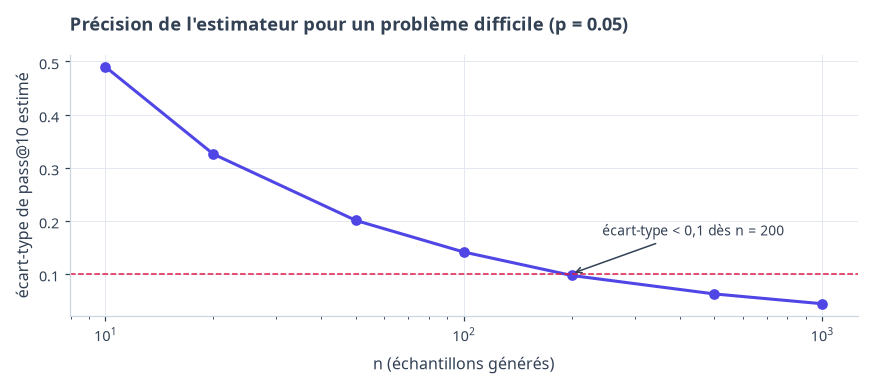

In [10]:
print({k: round(ev.pass_at_k(10, 3, k), 4) for k in [1, 3, 5]})
p, k = 0.05, 10
ns = [10, 20, 50, 100, 200, 500, 1000]
sd = [np.std([ev.pass_at_k(n, int(rng.binomial(n, p)), k) for _ in range(5000)]) for n in ns]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ns, sd, "o-", color=INDIGO)
ax.axhline(0.1, color=ROSE, ls="--", lw=1)
n_ok = next(n for n, s in zip(ns, sd) if s < 0.1)
ax.annotate(f"écart-type < 0,1 dès n = {n_ok}", (n_ok, 0.1), (20, 25), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color=SLATE), fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("n (échantillons générés)"); ax.set_ylabel("écart-type de pass@10 estimé")
ax.set_title(f"Précision de l'estimateur pour un problème difficile (p = {p})")
plt.tight_layout(); plt.show()

In [11]:
# Question 4 : simulation de deux modèles corrélés sur 164 problèmes
n_pb = 164
diffs = []
for _ in range(5000):
    facilite = rng.normal(0, 1.2, n_pb)                     # facilité commune des problèmes
    pa = 1 / (1 + np.exp(-(facilite - 0.2)))
    pb_ = 1 / (1 + np.exp(-(facilite - 0.2)))                  # MÊME capacité réelle
    diffs.append((rng.random(n_pb) < pb_).mean() - (rng.random(n_pb) < pa).mean())
diffs = np.array(diffs)
print(f"Deux modèles de même capacité : écart de pass@1 >= 3 points dans {np.mean(np.abs(diffs) >= 0.03):.0%} des cas "
      f"(écart-type de la différence : {diffs.std():.3f})")

Deux modèles de même capacité : écart de pass@1 >= 3 points dans 57% des cas (écart-type de la différence : 0.049)


Même pour deux modèles **de capacité identique**, un écart d'au moins 3 points apparaît
par simple hasard dans une large fraction des cas (plus d'une fois sur deux ici, avec une seule génération
par problème). Les écarts de quelques points sur de petits benchmarks doivent être
accompagnés d'intervalles de confiance, sujet repris au chapitre 4.

> **À retenir.** Le calcul de pass@k est élémentaire ; son interprétation demande de la
> prudence : la variance vient surtout du nombre de problèmes, et quelques points d'écart
> sur 164 problèmes ne prouvent rien.

## Exercice 3.6 : Un vérificateur de réponses courtes plus robuste

**Énoncé.** On évalue un assistant sur des questions à réponse courte (calculs, dates,
faits). Le cours 2 a montré que la correspondance exacte rejette des réponses correctes
et que l'inclusion accepte des réponses fausses.

1. Écrire un vérificateur `verifie(sortie, reference)` qui : pour une référence
   numérique, extrait le **dernier nombre** de la sortie et le compare numériquement ;
   sinon, accepte si la référence normalisée apparaît comme mot entier **et** que la
   sortie ne contient pas de négation de la référence.
2. Le comparer à la correspondance exacte normalisée et à l'inclusion sur un jeu de
   16 sorties étiquetées à la main (précision, rappel).
3. L'appliquer à de vraies réponses de Qwen2.5-0.5B-Instruct.

**Rappels.** Correspondance exacte, normalisation SQuAD, variante « contient » et ses
faux positifs (section *Exact match*, cours 2 section 5).

**Solution.** Les pièges à couvrir : unités et mots autour du nombre (« 132 apples »),
séparateurs de milliers, raisonnement qui cite d'autres nombres avant la réponse finale,
négations (« not Paris »), dates partielles (Anne Frank).

In [12]:
import re

def dernier_nombre(s):
    nums = re.findall(r"-?\d[\d,]*\.?\d*", s)
    return float(nums[-1].replace(",", "").rstrip(".")) if nums else None


def verifie(sortie, reference):
    try:
        ref = float(reference)
        x = dernier_nombre(sortie)
        return x is not None and abs(x - ref) < 1e-9
    except ValueError:
        s, r = ev.normalize_answer(sortie), ev.normalize_answer(reference)
        trouve = re.search(rf"\b{re.escape(r)}\b", s) is not None
        nie = re.search(rf"\b(not|never|no|isnt)\s+(\w+\s+){{0,2}}{re.escape(r)}\b", s) is not None
        return trouve and not nie


jeu = [  # (sortie, référence, correcte selon un humain)
    ("132", "132", True), ("The answer is 132.", "132", True), ("12 x 11 = 132 apples", "132", True),
    ("12 times 10 is 120, plus 12 gives 132.", "132", True), ("I think it is 122.", "132", False),
    ("It is 1,500 meters.", "1500", True), ("Roughly 15 or so", "1500", False),
    ("1929", "1929", True), ("September 12, 1929", "1929", False), ("Born in 1929.", "1929", True),
    ("Paris", "Paris", True), ("The capital is Paris.", "Paris", True), ("Not Paris, but Lyon.", "Paris", False),
    ("Lyon", "Paris", False), ("It's definitely not Canberra; it's Sydney.", "Canberra", False),
    ("Canberra, since 1913.", "Canberra", True),
]
J = pd.DataFrame(jeu, columns=["sortie", "reference", "humain"])
J["exacte"] = [ev.exact_match(s, r) for s, r, _ in jeu]
J["contient"] = [ev.contains_match(s, r) for s, r, _ in jeu]
J["verifie"] = [verifie(s, r) for s, r, _ in jeu]


def prec_rappel(pred, vrai):
    tp = np.sum(pred & vrai)
    return dict(precision=tp / max(1, pred.sum()), rappel=tp / max(1, vrai.sum()), exactitude=np.mean(pred == vrai))


PR = pd.DataFrame({m: prec_rappel(J[m].values, J.humain.values) for m in ["exacte", "contient", "verifie"]}).T
PR

,precision,rappel,exactitude
exacte,1.0000,0.3,0.5625
contient,0.7692,1.0,0.8125
verifie,0.9091,1.0,0.9375


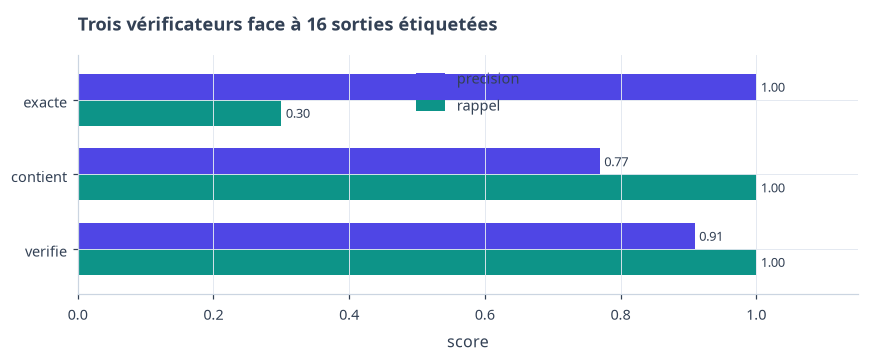

,sortie,reference,humain,exacte,contient,verifie
8,"September 12, 1929",1929,False,False,True,True


In [13]:
fig, ax = plt.subplots(figsize=(8, 3.4))
PR[["precision", "rappel"]].plot.barh(ax=ax, color=[INDIGO, TEAL], width=0.7)
ax.set_xlim(0, 1.15); ax.set_xlabel("score"); ax.invert_yaxis()
annotate_bars(ax, "{:.2f}", fontsize=8.5)
ax.set_title("Trois vérificateurs face à 16 sorties étiquetées")
plt.tight_layout(); plt.show()
J[J.verifie != J.humain]

La correspondance exacte est précise mais rate presque toutes les bonnes réponses
formulées en phrase (rappel faible) ; l'inclusion retrouve tout mais accepte des réponses
fausses (précision faible). Le vérificateur dédié combine les deux qualités sur ce jeu.
Les éventuelles erreurs restantes (tableau ci-dessus) montrent ses limites : la date
d'Anne Frank reste un piège pour toute règle lexicale, car la bonne année y figure. Un
vérificateur n'est jamais fini : on l'**évalue** sur des cas étiquetés, comme un modèle.

**Question 3 : application à Qwen.**

In [14]:
questions = [("What is 12 times 11?", "132"), ("What is 1000 plus 500?", "1500"), ("What is 7 squared?", "49"),
             ("In which year did World War II end?", "1945"), ("What is the capital of Australia?", "Canberra"),
             ("What is the chemical symbol of gold?", "Au"), ("How many continents are there?", "7"),
             ("Who painted the Mona Lisa?", "Leonardo da Vinci")]
rows = []
for q, ref in questions:
    out = llm.chat(q + " Answer briefly.", max_new_tokens=40)
    rows.append(dict(question=q, sortie=out[:70], exacte=ev.exact_match(out, ref), contient=ev.contains_match(out, ref),
                     verifie=verifie(out, ref)))
QW = pd.DataFrame(rows)
QW

,question,sortie,exacte,contient,verifie
0,What is 12 times 11?,12 times 11 equals 132.,False,True,True
1,What is 1000 plus 500?,1000 + 500 = 1500,False,True,True
2,What is 7 squared?,The square of 7 is 49.,False,True,True
3,In which year did World War II end?,"World War II ended in 1945, also known as the ...",False,True,True
4,What is the capital of Australia?,The capital of Australia is Canberra.,False,True,True
5,What is the chemical symbol of gold?,The chemical symbol for gold is Au.,False,True,True
6,How many continents are there?,"There are 5 continents: Asia, Africa, North Am...",False,False,False
7,Who painted the Mona Lisa?,The Mona Lisa was painted by Leonardo da Vinci.,False,True,True


Sur de vraies sorties, l'écart entre métriques peut être important : le taux de « bonnes
réponses » annoncé dépend du vérificateur autant que du modèle. Il faut donc toujours
publier la règle de correspondance avec le score, et vérifier à la main un échantillon
des désaccords entre règles.

> **À retenir.** Une métrique « exacte » repose sur une règle de correspondance qui
> doit elle-même être conçue, testée sur des cas étiquetés (précision et rappel) et
> documentée avec le score.

In [15]:
llm.free_gpu()